# 04 — Decision Tree

**Hướng dẫn cho thành viên phụ trách:**
- Chọn kernel `.venv` của dự án và chạy **Restart & Run All** từ đầu đến cuối.
- Toàn bộ dữ liệu, chia tập (80/20) và `preprocessor` được nạp thống nhất từ thư mục `src/` (`src/config.py`, `src/data.py`, `src/modeling.py`) để **không lặp code** và đảm bảo **0% data leakage**.
- **Quy tắc bắt buộc:** Các thí nghiệm E1–E6 bên dưới chỉ sử dụng **tập Train (40.837 dòng)** qua 5-fold Stratified CV. **Tuyệt đối không dùng tập Test** để chọn mô hình hay chỉnh tham số.
- Kết quả tóm tắt sẽ tự động lưu tại `results/metrics/04_decision_tree.json` để notebook `07_comparison.ipynb` tổng hợp.

## 1. Nạp dữ liệu từ `src/` & Cấu hình mô hình
Thành viên có thể mở rộng thêm siêu tham số trong `PARAM_SPACE` nếu muốn khảo sát sâu hơn.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import RANDOM_STATE, SCORING, make_cv
from src.data import load_train_test
from src.modeling import (
    build_preprocessor,
    make_pipeline,
    evaluate_cv,
    scan_oof_thresholds,
    save_cv_report,
)

X_train, X_test, y_train, y_test, NUM_COLS, CAT_COLS = load_train_test()
preprocessor = build_preprocessor(NUM_COLS, CAT_COLS, min_frequency=50)
cv = make_cv()

MODEL_NAME = "Decision Tree"
REPORT_FILE = "04_decision_tree.json"
BASE_MODEL = DecisionTreeClassifier(random_state=RANDOM_STATE)
PARAM_SPACE = {
    "model__max_depth": [4, 6, 8, 12, 18, None],
    "model__min_samples_leaf": [5, 15, 30, 50],
    "model__ccp_alpha": [0.0, 0.0001, 0.001],
    "model__class_weight": [None, "balanced"],
}

print(f"Ready | {MODEL_NAME} | Train={X_train.shape} | Test={X_test.shape} | Churn={y_train.mean():.4f}")

Ready | Decision Tree | Train=(40837, 53) | Test=(10210, 53) | Churn=0.2882


## 2. E1 — Baseline 5-fold CV
Đánh giá mô hình mặc định trên 5 thước đo: `f1`, `recall`, `precision`, `roc_auc`, `ap` (PR-AUC).

In [2]:
t0 = time.time()
baseline_pipe = make_pipeline(preprocessor, BASE_MODEL)
base_cv, base_summary = evaluate_cv(baseline_pipe, X_train, y_train, cv)
print(f"E1 xong sau {time.time() - t0:.1f}s")
display(base_summary)

E1 xong sau 41.8s


,metric,mean,std
0,f1,0.3572,0.0059
1,recall,0.3581,0.0056
2,precision,0.3564,0.0068
3,roc_auc,0.5481,0.0045
4,ap,0.3126,0.0028


## 3. E2 — Hyperparameter Tuning (`RandomizedSearchCV (n_iter=15)`)
Tối ưu F1 trên tập Train (bao gồm cả `class_weight` để so sánh công bằng). Kiểm tra chênh lệch `mean_train_score` và `mean_test_score` để phát hiện overfitting.

In [3]:
t0 = time.time()
search = RandomizedSearchCV(
    estimator=clone(baseline_pipe),
    param_distributions=PARAM_SPACE,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)
search.fit(X_train, y_train)

best_model = clone(search.best_estimator_.named_steps["model"])
tuned_cv, tuned_summary = evaluate_cv(make_pipeline(preprocessor, best_model), X_train, y_train, cv)

print(f"E2 xong sau {time.time() - t0:.1f}s | Best CV F1: {search.best_score_:.4f}")
print("Best params:", search.best_params_)
display(
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")[["params", "mean_train_score", "mean_test_score", "std_test_score"]]
    .head(8)
    .round(4)
)
display(tuned_summary)

E2 xong sau 140.6s | Best CV F1: 0.4843
Best params: {'model__min_samples_leaf': 5, 'model__max_depth': 12, 'model__class_weight': 'balanced', 'model__ccp_alpha': 0.001}


,params,mean_train_score,mean_test_score,std_test_score
6,"{'model__min_samples_leaf': 5, 'model__max_dep...",0.4848,0.4843,0.0040
13,"{'model__min_samples_leaf': 15, 'model__max_de...",0.4848,0.4843,0.0040
11,"{'model__min_samples_leaf': 30, 'model__max_de...",0.4919,0.4751,0.0132
2,"{'model__min_samples_leaf': 30, 'model__max_de...",0.5026,0.4667,0.0138
12,"{'model__min_samples_leaf': 30, 'model__max_de...",0.5811,0.4423,0.0084
9,"{'model__min_samples_leaf': 30, 'model__max_de...",0.4604,0.3029,0.0103
7,"{'model__min_samples_leaf': 15, 'model__max_de...",0.4816,0.2975,0.0099
8,"{'model__min_samples_leaf': 30, 'model__max_de...",0.4077,0.2879,0.0196


,metric,mean,std
0,f1,0.4843,0.0040
1,recall,0.8017,0.0078
2,precision,0.3469,0.0035
3,roc_auc,0.6237,0.0074
4,ap,0.3686,0.0055


## 4. E3 — Xử lý mất cân bằng lớp
So sánh `baseline` với `class_weight="balanced"` và `SMOTE` (đặt bên trong `ImbPipeline` để chỉ oversample trên từng fold huấn luyện).

In [4]:
t0 = time.time()
weighted_pipe = make_pipeline(
    preprocessor,
    clone(BASE_MODEL).set_params(class_weight="balanced"),
)
weighted_cv, _ = evaluate_cv(weighted_pipe, X_train, y_train, cv)

smote_pipe = ImbPipeline([
    ("preprocessor", clone(preprocessor)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", clone(BASE_MODEL)),
])
smote_cv, _ = evaluate_cv(smote_pipe, X_train, y_train, cv)

display(
    pd.DataFrame({
        "metric": list(SCORING),
        "baseline": [base_cv[f"test_{k}"].mean() for k in SCORING],
        "class_weight_balanced": [weighted_cv[f"test_{k}"].mean() for k in SCORING],
        "smote": [smote_cv[f"test_{k}"].mean() for k in SCORING],
    }).round(4)
)
print(f"E3 xong sau {time.time() - t0:.1f}s")

,metric,baseline,class_weight_balanced,smote
0,f1,0.3572,0.3623,0.3565
1,recall,0.3581,0.3672,0.3704
2,precision,0.3564,0.3577,0.3437
3,roc_auc,0.5481,0.5502,0.5420
4,ap,0.3126,0.3138,0.3088


E3 xong sau 119.1s


## 5. E4 — Feature Selection (`SelectPercentile`)
Thử giữ lại top 60% đặc trưng theo `f_classif` bên trong pipeline CV trên mô hình đã tune để đánh giá mức độ ảnh hưởng đến F1 và thời gian chạy.

In [5]:
t0 = time.time()
fs_pipe = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selector", SelectPercentile(score_func=f_classif, percentile=60)),
    ("model", clone(best_model)),
])
fs_cv, _ = evaluate_cv(fs_pipe, X_train, y_train, cv)

display(
    pd.DataFrame({
        "metric": list(SCORING),
        "tuned_full": [tuned_cv[f"test_{k}"].mean() for k in SCORING],
        "tuned_top60pct": [fs_cv[f"test_{k}"].mean() for k in SCORING],
    }).round(4)
)
print(f"E4 xong sau {time.time() - t0:.1f}s")

,metric,tuned_full,tuned_top60pct
0,f1,0.4843,0.4843
1,recall,0.8017,0.8017
2,precision,0.3469,0.3469
3,roc_auc,0.6237,0.6237
4,ap,0.3686,0.3686


E4 xong sau 11.0s


## 6. E5 — Stability Analysis qua 5 fold
Kiểm tra độ ổn định của F1 và ROC-AUC giữa 5 fold.

,fold,baseline_f1,tuned_f1,tuned_roc_auc
0,1,0.3557,0.4922,0.6380
1,2,0.3660,0.4822,0.6216
2,3,0.3525,0.4834,0.6164
3,4,0.3618,0.4820,0.6201
4,5,0.3500,0.4814,0.6223


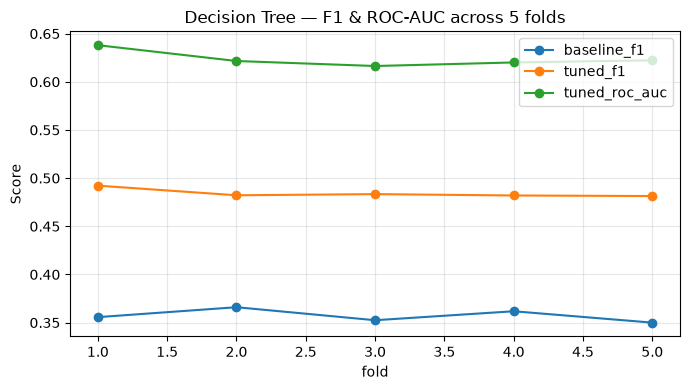

In [6]:
stability = pd.DataFrame({
    "fold": range(1, 6),
    "baseline_f1": base_cv["test_f1"],
    "tuned_f1": tuned_cv["test_f1"],
    "tuned_roc_auc": tuned_cv["test_roc_auc"],
}).round(4)
display(stability)

ax = stability.set_index("fold").plot(
    marker="o", figsize=(7, 4), title=f"{MODEL_NAME} — F1 & ROC-AUC across 5 folds"
)
ax.set_ylabel("Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. E6 — Threshold Analysis (OOF trên Train) & Lưu `04_decision_tree.json`
Quét ngưỡng quyết định trên xác suất out-of-fold của tập Train (không chạm tập Test), sau đó xuất báo cáo JSON để notebook `07_comparison.ipynb` đọc tự động.

In [7]:
t0 = time.time()
thresh_df, best_threshold, best_oof_f1 = scan_oof_thresholds(
    preprocessor, best_model, X_train, y_train, cv
)
print(f"E6 xong sau {time.time() - t0:.1f}s | Best OOF threshold: {best_threshold} (F1={best_oof_f1:.4f})")
display(thresh_df)

def _py_val(v):
    if isinstance(v, np.integer):
        return int(v)
    if isinstance(v, np.floating):
        return float(v)
    return v

report = {
    "model": MODEL_NAME,
    "baseline_cv": {k: round(float(base_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "weighted_cv": {k: round(float(weighted_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "smote_cv": {k: round(float(smote_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "tuned_cv": {k: round(float(tuned_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "tuned_cv_f1_std": round(float(tuned_cv["test_f1"].std()), 4),
    "tuned_best_cv_f1": round(float(search.best_score_), 4),
    "tuned_best_params": {
        k.replace("model__", ""): _py_val(v)
        for k, v in search.best_params_.items()
    },
    "best_oof_threshold": best_threshold,
    "best_oof_f1_at_threshold": round(best_oof_f1, 4),
}

saved_path = save_cv_report(REPORT_FILE, report)
print("Đã lưu kết quả CV tại:", saved_path)

E6 xong sau 11.7s | Best OOF threshold: 0.4 (F1=0.4845)


,threshold,precision,recall,f1
0,0.15,0.2882,1.0000,0.4474
1,0.20,0.2882,1.0000,0.4474
2,0.25,0.2882,1.0000,0.4474
3,0.30,0.3175,0.9249,0.4727
4,0.35,0.3175,0.9249,0.4727
5,0.40,0.3414,0.8339,0.4845
6,0.45,0.3443,0.8147,0.4840
7,0.50,0.3469,0.8017,0.4842
8,0.55,0.4073,0.2803,0.3321
9,0.60,0.4328,0.2038,0.2771


Đã lưu kết quả CV tại: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\metrics\04_decision_tree.json


## 8. Nhận xét dành cho báo cáo (Thành viên tự điền sau khi chạy)
- **E1 (Baseline):** F1, Recall, Precision, ROC-AUC, PR-AUC đạt bao nhiêu? Có hiện tượng thiên lệch về lớp `0` không?
- **E2 (Tuning):** Siêu tham số tối ưu là gì? Chênh lệch `mean_train_score` vs `mean_test_score` có cho thấy overfitting hay không?
- **E3 (Mất cân bằng lớp):** So sánh hiệu quả giữa `class_weight="balanced"` và `SMOTE` (đánh đổi Precision vs Recall và thời gian chạy).
- **E4 (Feature Selection):** Giữ 60% đặc trưng làm tăng hay giảm F1? Có đáng rút gọn không?
- **E5 & E6 (Ổn định & Ngưỡng):** Độ lệch chuẩn giữa 5 fold là bao nhiêu? Ngưỡng OOF tối ưu khác gì so với ngưỡng mặc định `0.50`?

> *Lưu ý: Không khẳng định mô hình nào tốt nhất trước khi tổng hợp công bằng ở `07_comparison.ipynb`.*